In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
import sys
print(sys.executable)


d:\fake-discount-detector\venv\Scripts\python.exe


In [3]:
import sys
print(sys.executable)


d:\fake-discount-detector\venv\Scripts\python.exe


In [4]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 3.0.6


In [5]:
import pandas as pd

import os
DATA_DIR = 'data' if os.path.exists('data') else ('../data' if os.path.exists('../data') else 'data')
df = pd.read_csv(os.path.join(DATA_DIR, "dishwashers_historical_clean.csv")

df.head()

,product_model,vendor,date,price_eur,product_id
0,Siemens iQ300 SN53ES14VE,Alternate.at,2024-06-26,494.00,siemens_iq300_sn53es14ve
1,Siemens iQ300 SN53ES14VE,Amazon.at,2024-06-26,504.19,siemens_iq300_sn53es14ve
2,Siemens iQ300 SN53ES14VE,Köck,2024-06-26,511.48,siemens_iq300_sn53es14ve
3,Siemens iQ300 SN53ES14VE,Servicehansa,2024-06-26,511.48,siemens_iq300_sn53es14ve
4,Siemens iQ300 SN53ES14VE,akatronik,2024-06-26,529.00,siemens_iq300_sn53es14ve


In [6]:
df.shape

(26581, 5)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26581 entries, 0 to 26580
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_model  26581 non-null  str    
 1   vendor         26581 non-null  str    
 2   date           26581 non-null  str    
 3   price_eur      26581 non-null  float64
 4   product_id     26581 non-null  str    
dtypes: float64(1), str(4)
memory usage: 1.0 MB


In [8]:
df.describe()

,price_eur
count,26581.000000
mean,976.846923
std,603.550830
min,210.170000
25%,599.000000
50%,810.000000
75%,1190.000000
max,7080.000000


In [9]:
df["product_id"].nunique()

1691

In [10]:
df.isnull().sum()

product_model    0
vendor           0
date             0
price_eur        0
product_id       0
dtype: int64

In [11]:
df["vendor"].nunique()

89

In [12]:
df["date"].value_counts().sort_index()

date
2024-06-26    10594
2024-07-26     8289
2024-08-26     7698
Name: count, dtype: int64

In [13]:
df["date"] = pd.to_datetime(df["date"])

print("Start date:", df["date"].min())
print("End date:", df["date"].max())
print("Number of dates:", df["date"].nunique())

Start date: 2024-06-26 00:00:00
End date: 2024-08-26 00:00:00
Number of dates: 3


In [14]:
df["vendor"].nunique()

89

In [15]:
df["vendor"].value_counts().head(15)

vendor
Köck                          2056
Servicehansa                  1319
Radio Krejcik Wien            1318
OTTO Österreich               1138
Elektroshop Wagner AT         1133
Universal Versand             1130
Media Markt.at                1012
Amazon.at                      931
Küchen & Wohnstudio Kutzer     849
electronic4you                 813
0815                           792
Alternate.at                   692
e-tec.at                       682
Mybauer.at                     680
ek-online                      623
Name: count, dtype: int64

### 1. Data Type Conversion
To perform time-series analysis and analyze price history, we need to ensure the `date` column is properly formatted as a Pandas datetime object.

In [16]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')

### 2. Temporal Range
We need to understand the timeframe of our dataset. This tells us over what period we are observing the historical prices.

In [17]:
print("Earliest date:", df['date'].min())
print("Latest date:", df['date'].max())
print("Number of unique dates:", df['date'].nunique())

Earliest date: 2024-06-26 00:00:00
Latest date: 2024-08-26 00:00:00
Number of unique dates: 3


### 3. Historical Observations per Product
For a Fake Discount Detector, we need sufficient historical data for a product to establish a reliable baseline price. Products with very few observations might not be suitable for our analysis.

In [18]:
# Number of unique dates per product
obs_per_product = df.groupby('product_id')['date'].nunique().reset_index(name='num_observations')

display(obs_per_product.describe())

# Distribution/count of products by number of observations
display(obs_per_product['num_observations'].value_counts().sort_index())

,num_observations
count,1691.000000
mean,1.794796
std,0.958239
min,1.000000
25%,1.000000
50%,1.000000
75%,3.000000
max,3.000000


num_observations
1    985
2     68
3    638
Name: count, dtype: int64

### 4. Top Products by Number of Observations
Let's find the products that have the most historical price data. These are the best candidates for observing price behavior.

In [19]:
top_10_products = obs_per_product.sort_values(by='num_observations', ascending=False).head(10)
display(top_10_products)

,product_id,num_observations
11,aeg_electrolux_fee73407zm,3
1690,zanussi_zssn121x1,3
0,aeg_electrolux_fav55bvi3p,3
1,aeg_electrolux_fav55vi3p,3
2,aeg_electrolux_feb52620zm,3
3,aeg_electrolux_feb52630zm,3
4,aeg_electrolux_fee53610zm,3
5,aeg_electrolux_fee53628zm,3
12,aeg_electrolux_fee7341azm,3
7,aeg_electrolux_fee62417zm,3


### 5. Selecting the Most Observed Product
To understand the data on an individual product level, we will isolate the history of the product with the highest number of observations. This dataframe will contain just its history.

In [20]:
most_observed_product_id = top_10_products.iloc[0]['product_id']
product_history = df[df['product_id'] == most_observed_product_id][['date', 'vendor', 'price_eur', 'product_id']].sort_values(by='date')

### 6. Displaying the Selected Product's History
Let's look at the actual price records for our selected product over time.

In [21]:
display(product_history)

,date,vendor,price_eur,product_id
8458,2024-06-26,Elektro Outlet Steyr,529.00,aeg_electrolux_fee73407zm
8478,2024-06-26,Elektroshop Wagner AT,614.35,aeg_electrolux_fee73407zm
8477,2024-06-26,Servicehansa,559.00,aeg_electrolux_fee73407zm
8476,2024-06-26,Küchen & Wohnstudio Kutzer,559.00,aeg_electrolux_fee73407zm
8475,2024-06-26,Köck,559.00,aeg_electrolux_fee73407zm
8473,2024-06-26,mörth online,529.00,aeg_electrolux_fee73407zm
8472,2024-06-26,Elektro Outlet Steyr,529.00,aeg_electrolux_fee73407zm
8474,2024-06-26,Mybauer.at,537.18,aeg_electrolux_fee73407zm
8463,2024-06-26,Servicehansa,559.00,aeg_electrolux_fee73407zm
8462,2024-06-26,Küchen & Wohnstudio Kutzer,559.00,aeg_electrolux_fee73407zm


### 7. Price Changes Over Time
Visualizing the price history helps us spot trends, normal price fluctuations, and sudden drops (which could be real or fake discounts).

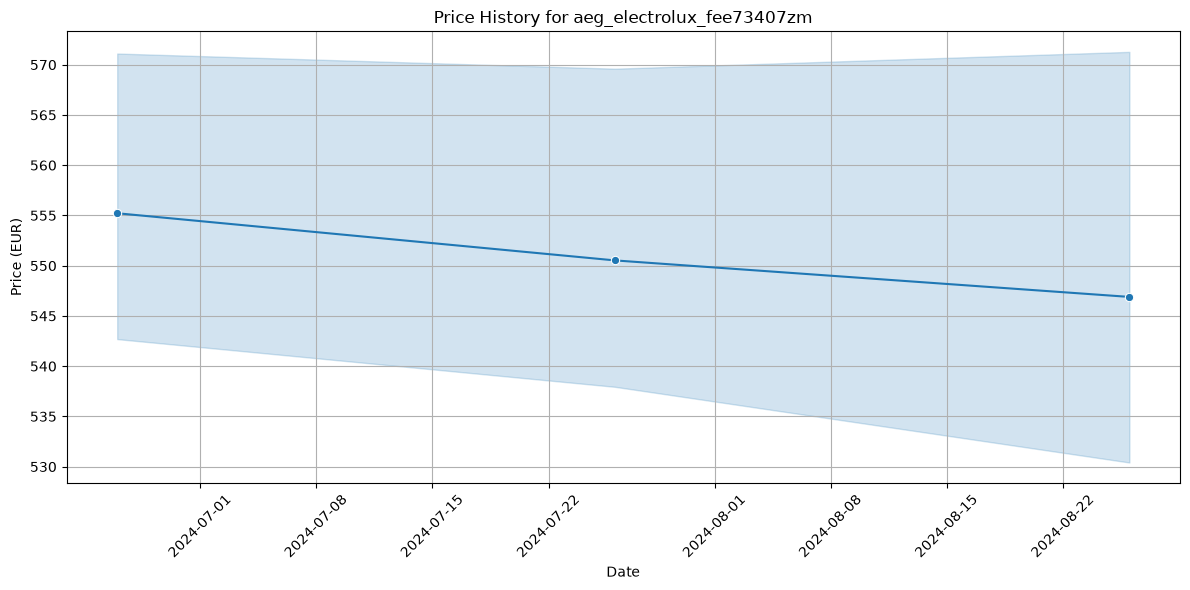

In [22]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=product_history, x='date', y='price_eur', marker='o')
plt.title(f'Price History for {most_observed_product_id}')
plt.xlabel('Date')
plt.ylabel('Price (EUR)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8. Overall Price Distribution
Understanding the general distribution of prices in our dataset gives us context. It helps us see if we are dealing with budget items, luxury items, or a wide mix.

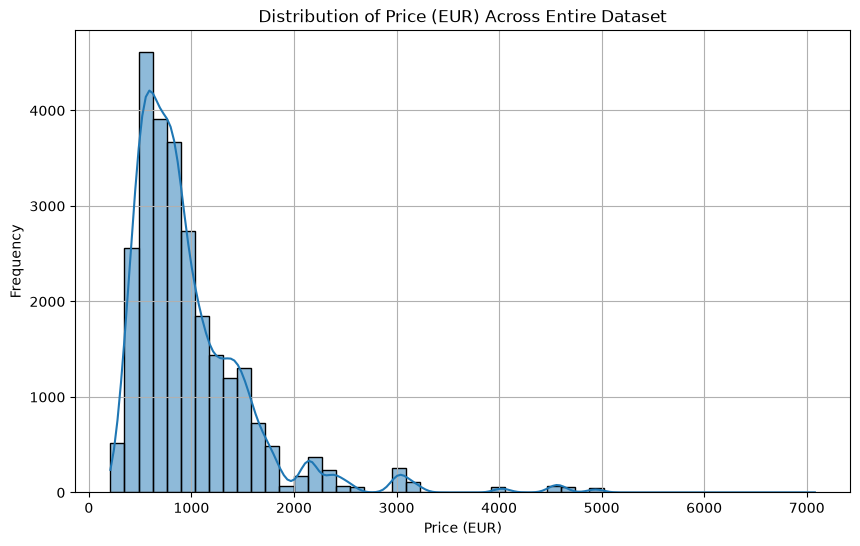

In [23]:
plt.figure(figsize=(10, 6))
sns.histplot(df['price_eur'], bins=50, kde=True)
plt.title('Distribution of Price (EUR) Across Entire Dataset')
plt.xlabel('Price (EUR)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

### 9. Price Statistics for the Selected Product
Calculating these statistics helps us establish what a "normal" price is for this specific product, what the absolute lowest price has been, and how much it typically varies.

In [24]:
min_price = product_history['price_eur'].min()
max_price = product_history['price_eur'].max()
mean_price = product_history['price_eur'].mean()
median_price = product_history['price_eur'].median()
std_price = product_history['price_eur'].std()
pct_diff = ((max_price - min_price) / min_price) * 100

print(f"Minimum Price: {min_price:.2f} EUR")
print(f"Maximum Price: {max_price:.2f} EUR")
print(f"Mean Price: {mean_price:.2f} EUR")
print(f"Median Price: {median_price:.2f} EUR")
print(f"Standard Deviation: {std_price:.2f} EUR")
print(f"Percentage difference (Max vs Min): {pct_diff:.2f}%")

Minimum Price: 529.00 EUR
Maximum Price: 614.35 EUR
Mean Price: 551.82 EUR
Median Price: 538.90 EUR
Standard Deviation: 27.82 EUR
Percentage difference (Max vs Min): 16.13%


### EDA Summary
Based on the exploratory data analysis, here are the important observations regarding the dataset's suitability for a Fake Discount Detector:
- **Temporal Range**: The dataset spans a specific timeframe, which dictates the historical context we can use to evaluate "recent" discounts. If the timeframe is too short, we might miss seasonal price variations.
- **Observations per Product**: Products vary in how frequently they are observed. We must ensure a product has enough data points before attempting to identify a misleading discount. Products with too few observations do not have a reliable "baseline" price.
- **Price Fluctuations**: As seen in the individual product history, prices naturally fluctuate. A "fake discount" algorithm needs to distinguish between a regular minor price change, a genuine steep drop, and a manipulated baseline (e.g. inflating the price right before a sale).
- **Vendor Variations**: A single product can have multiple prices on the same day across different vendors. We might need to track vendor-specific price history rather than an aggregated history to accurately spot a fake discount from a specific seller.